# Hybrid AI-Powered Phishing Detection and Explanation System
## Assignment 6, Step 2 — Machine Learning Experiments

**Research question:** Can combining a machine learning phishing detection model with an AI explanation assistant improve users' understanding of phishing threats while maintaining reliable detection performance?

This notebook is Step 2 of the Assignment 6 research project. It trains and evaluates the machine-learning **detection layer** of the proposed hybrid system, and lays the explanation groundwork (per-prediction feature attribution) that the AI assistant will use in a later step.

**What this notebook produces**

1. Dataset loading and cleaning (verified against the Midterm project).
2. Replication of the Midterm baseline (Decision Tree + Random Forest) with an honest check against the reference accuracies.
3. Training of four additional models: Logistic Regression, Gradient Boosting, k-Nearest Neighbors, SVM.
4. A full comparison: accuracy, precision, recall, F1, confusion matrices, training/prediction time, and 5-fold cross-validation.
5. Explanation groundwork: per-feature contributions for sample predictions.
6. Machine-readable results written to `results/experiments_results.json`.

**Honesty rules followed here**

- Every number printed in this notebook is computed by running its cells. Nothing is copied from a previous report as if it were a new result.
- Midterm reference accuracies appear only as clearly labeled verification targets.
- The hybrid system (classifier + AI explanation assistant) has **not** been implemented or evaluated yet — its result fields are saved as `null` with status `not-yet-implemented`.

**Credits:** Web Page Phishing Dataset by **Daniel Fernandon** (Kaggle). Reference notebook: "Advanced URL Analysis for Phishing Detection" by **mrudhuhas** (Kaggle). Neither was created by me.

In [1]:
# Setup — works in Google Colab and locally (Assignment6/ folder of the repo).
import importlib, subprocess, sys

def ensure(pkg, import_name=None):
    try:
        importlib.import_module(import_name or pkg)
    except ImportError:
        print(f"Installing {pkg} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

ensure("pandas")
ensure("numpy")
ensure("scikit-learn", "sklearn")
ensure("matplotlib")

import json, time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_recall_fscore_support)
from sklearn.model_selection import GroupShuffleSplit, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

IN_COLAB = "google.colab" in sys.modules
RANDOM_STATE = 42

print(f"Python      : {sys.version.split()[0]}")
print(f"pandas      : {pd.__version__}")
print(f"numpy       : {np.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"matplotlib  : {matplotlib.__version__}")
print(f"Running in  : {'Google Colab' if IN_COLAB else 'local Python'}")

Matplotlib is building the font cache; this may take a moment.


Python      : 3.13.3
pandas      : 3.0.6
numpy       : 2.5.4
scikit-learn: 1.9.1
matplotlib  : 3.11.2
Running in  : local Python


## 1. Load and clean the dataset

The **Web Page Phishing Dataset** contains 100,077 rows, 19 numeric URL features and one label (`phishing`: 0 = legitimate, 1 = phishing). As in the Midterm project, exact duplicate rows are removed before modeling (100,077 -> 21,891 rows). The counts are verified below.

In [2]:
# Locate the CSV: works locally (repo layout) and in Colab (upload to /content).
candidates = [
    Path("web-page-phishing.csv"),
    Path("/content/web-page-phishing.csv"),
    Path("../Midterm/Phishing-Website-Detection/data/web-page-phishing.csv"),
    Path("Midterm/Phishing-Website-Detection/data/web-page-phishing.csv"),
]
CSV_PATH = next((p for p in candidates if p.exists()), None)

if CSV_PATH is None and IN_COLAB:
    print("CSV not found. Upload web-page-phishing.csv (Kaggle download) to Colab.")
    from google.colab import files
    uploaded = files.upload()
    CSV_PATH = Path(next(iter(uploaded)))

if CSV_PATH is None:
    raise FileNotFoundError(
        "web-page-phishing.csv not found. Download it from "
        "https://www.kaggle.com/datasets/danielfernandon/web-page-phishing-dataset "
        "and place it next to this notebook (or in /content in Colab)."
    )

df_raw = pd.read_csv(CSV_PATH)
print(f"Dataset file  : {CSV_PATH}")
print(f"Original shape: {df_raw.shape}")
print(f"Missing values: {int(df_raw.isnull().sum().sum())}")
n_dupes = int(df_raw.duplicated().sum())
print(f"Duplicate rows: {n_dupes:,}")

df = df_raw.drop_duplicates().copy()
print(f"Cleaned shape : {df.shape}")

# Verify the same cleaning result as the Midterm project.
assert df.shape[0] == 21891, f"Expected 21,891 cleaned rows (Midterm count), got {df.shape[0]}"

counts = df["phishing"].value_counts().sort_index()
print("\nCleaned class distribution:")
print(f"  0 legitimate : {counts.get(0, 0):,}")
print(f"  1 phishing   : {counts.get(1, 0):,}")

Dataset file  : ../Midterm/Phishing-Website-Detection/data/web-page-phishing.csv
Original shape: (100077, 20)
Missing values: 0
Duplicate rows: 78,186
Cleaned shape : (21891, 20)

Cleaned class distribution:
  0 legitimate : 6,019
  1 phishing   : 15,872


In [3]:
# Same group-based split as the Midterm project: rows with identical feature
# vectors always stay on the same side of the split (leakage control).
X = df.drop(columns=["phishing"])
y = df["phishing"]
FEATURE_ORDER = list(X.columns)

groups = pd.util.hash_pandas_object(X, index=False)
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Training rows: {len(X_train):,}   Testing rows: {len(X_test):,}")
test_phishing_share = float(y_test.mean())
print(f"Phishing share in test set: {test_phishing_share:.4f}")
print(f"Reference 'always say phishing' accuracy on this test set: {test_phishing_share:.4f}")

Training rows: 17,523   Testing rows: 4,368
Phishing share in test set: 0.7383
Reference 'always say phishing' accuracy on this test set: 0.7383


## 2. Replicate the Midterm baseline (honest verification)

The Midterm project reported **Decision Tree 81.41%** and **Random Forest 82.58%** accuracy. The code below retrains both models with the exact same pipeline, parameters and random seed, and compares the **actually computed** accuracies with those reference values.

> The reference numbers come from the Midterm notebook (run in Google Colab). A small difference here can occur when the scikit-learn version differs from Colab's; the notebook reports the real numbers either way.

In [4]:
REFERENCE_DT_ACCURACY = 0.8141025641025641   # reported in the Midterm notebook (81.41%)
REFERENCE_RF_ACCURACY = 0.8257783882783882   # reported in the Midterm notebook (82.58%)

baseline_dt = DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE)
baseline_rf = RandomForestClassifier(n_estimators=100, max_depth=10,
                                     random_state=RANDOM_STATE, n_jobs=-1)

t0 = time.perf_counter(); baseline_dt.fit(X_train, y_train); dt_fit = time.perf_counter() - t0
t0 = time.perf_counter(); baseline_rf.fit(X_train, y_train); rf_fit = time.perf_counter() - t0

dt_preds = baseline_dt.predict(X_test)
rf_preds = baseline_rf.predict(X_test)
dt_acc = accuracy_score(y_test, dt_preds)
rf_acc = accuracy_score(y_test, rf_preds)

print("BASELINE REPLICATION (computed in this run)")
print(f"  Decision Tree: {dt_acc:.4%}  (reference: {REFERENCE_DT_ACCURACY:.4%}, delta: {dt_acc - REFERENCE_DT_ACCURACY:+.4%})")
print(f"  Random Forest: {rf_acc:.4%}  (reference: {REFERENCE_RF_ACCURACY:.4%}, delta: {rf_acc - REFERENCE_RF_ACCURACY:+.4%})")
dt_exact = bool(dt_acc == REFERENCE_DT_ACCURACY)
rf_exact = bool(rf_acc == REFERENCE_RF_ACCURACY)
print(f"  Exact match  -- Decision Tree: {dt_exact} | Random Forest: {rf_exact}")

print("\nRANDOM FOREST CLASSIFICATION REPORT (this run)")
print(classification_report(y_test, rf_preds, target_names=["legitimate", "phishing"]))

BASELINE REPLICATION (computed in this run)
  Decision Tree: 81.4103%  (reference: 81.4103%, delta: +0.0000%)
  Random Forest: 82.5778%  (reference: 82.5778%, delta: +0.0000%)
  Exact match  -- Decision Tree: True | Random Forest: True

RANDOM FOREST CLASSIFICATION REPORT (this run)
              precision    recall  f1-score   support

  legitimate       0.75      0.50      0.60      1143
    phishing       0.84      0.94      0.89      3225

    accuracy                           0.83      4368
   macro avg       0.80      0.72      0.74      4368
weighted avg       0.82      0.83      0.81      4368



## 3. Train four additional models on the same split

To compare fairly, every model sees the identical group-based train/test split. Logistic Regression, k-NN and SVM are sensitive to feature scale, so they are wrapped in a `StandardScaler` fitted **on the training data only** (a pipeline). Tree-based models do not need scaling.

A `Dummy` classifier ("always predict the majority class") is included as a floor reference: a useful model must beat it.

In [5]:
models = {
    "Dummy (most-frequent)": DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE),
    "Decision Tree (baseline)": DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
    "Random Forest (baseline)": RandomForestClassifier(n_estimators=100, max_depth=10,
                                                       random_state=RANDOM_STATE, n_jobs=-1),
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "k-Nearest Neighbors": Pipeline([("scaler", StandardScaler()),
                                     ("clf", KNeighborsClassifier(n_neighbors=11, n_jobs=-1))]),
    "SVM (RBF kernel)": Pipeline([("scaler", StandardScaler()),
                                  ("clf", SVC(kernel="rbf", random_state=RANDOM_STATE))]),
}

records, predictions = [], {}
for name, model in models.items():
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    preds = model.predict(X_test)
    pred_s = time.perf_counter() - t0

    p, r, f1, _ = precision_recall_fscore_support(y_test, preds, average=None, labels=[0, 1])
    tn, fp, fn, tp = confusion_matrix(y_test, preds, labels=[0, 1]).ravel()
    records.append({
        "model": name,
        "accuracy": float(accuracy_score(y_test, preds)),
        "precision_phishing": float(p[1]), "recall_phishing": float(r[1]),
        "f1_phishing": float(f1[1]), "f1_macro": float(f1_score(y_test, preds, average="macro")),
        "fit_seconds": fit_s, "predict_seconds": pred_s,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    })
    predictions[name] = preds
    print(f"done: {name:26s} accuracy={records[-1]['accuracy']:.4f}  "
          f"fit={fit_s:.2f}s  predict={pred_s:.2f}s")

print("\nRemember: in security terms, recall_phishing (catching real phishing sites)")
print("and precision (not wrongly flagging legitimate sites) matter alongside accuracy.")

done: Dummy (most-frequent)      accuracy=0.7383  fit=0.00s  predict=0.00s
done: Decision Tree (baseline)   accuracy=0.8141  fit=0.07s  predict=0.00s


/Users/joselyncarvajal/TECH3498/Assignment6/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


done: Random Forest (baseline)   accuracy=0.8258  fit=0.55s  predict=0.05s
done: Logistic Regression        accuracy=0.7841  fit=0.14s  predict=0.01s


done: Gradient Boosting          accuracy=0.8214  fit=2.68s  predict=0.01s


done: k-Nearest Neighbors        accuracy=0.8237  fit=0.02s  predict=0.49s


done: SVM (RBF kernel)           accuracy=0.8139  fit=18.39s  predict=5.79s

Remember: in security terms, recall_phishing (catching real phishing sites)
and precision (not wrongly flagging legitimate sites) matter alongside accuracy.


## 4. Five-fold cross-validation (stability check)

A single split can be lucky. Stratified 5-fold cross-validation (shuffled, same seed) re-runs training five times on different folds and reports mean +/- standard deviation of accuracy and F1.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_records = []
for name, model in models.items():
    accs = cross_val_score(model, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
    f1s = cross_val_score(model, X, y, cv=cv, scoring="f1", n_jobs=-1)
    cv_records.append({
        "model": name,
        "cv_accuracy_mean": float(accs.mean()), "cv_accuracy_std": float(accs.std()),
        "cv_f1_mean": float(f1s.mean()), "cv_f1_std": float(f1s.std()),
    })
    print(f"{name:26s} CV accuracy: {accs.mean():.4f} +/- {accs.std():.4f}   "
          f"CV F1: {f1s.mean():.4f} +/- {f1s.std():.4f}")

Dummy (most-frequent)      CV accuracy: 0.7250 +/- 0.0001   CV F1: 0.8406 +/- 0.0001


Decision Tree (baseline)   CV accuracy: 0.8022 +/- 0.0031   CV F1: 0.8676 +/- 0.0034


Random Forest (baseline)   CV accuracy: 0.8147 +/- 0.0034   CV F1: 0.8801 +/- 0.0025


Logistic Regression        CV accuracy: 0.7774 +/- 0.0033   CV F1: 0.8530 +/- 0.0024


Gradient Boosting          CV accuracy: 0.8142 +/- 0.0035   CV F1: 0.8772 +/- 0.0026


k-Nearest Neighbors        CV accuracy: 0.7909 +/- 0.0077   CV F1: 0.8580 +/- 0.0059


SVM (RBF kernel)           CV accuracy: 0.8071 +/- 0.0036   CV F1: 0.8725 +/- 0.0027


## 5. Comparison — single split vs cross-validation

In [7]:
merged = pd.DataFrame(records).merge(pd.DataFrame(cv_records), on="model")
merged = merged.sort_values("accuracy", ascending=False).reset_index(drop=True)

show = pd.DataFrame({
    "model": merged["model"],
    "accuracy": merged["accuracy"].map("{:.4f}".format),
    "precision_phishing": merged["precision_phishing"].map("{:.4f}".format),
    "recall_phishing": merged["recall_phishing"].map("{:.4f}".format),
    "f1_phishing": merged["f1_phishing"].map("{:.4f}".format),
    "f1_macro": merged["f1_macro"].map("{:.4f}".format),
    "cv_accuracy_mean": merged["cv_accuracy_mean"].map("{:.4f}".format),
    "cv_accuracy_std": merged["cv_accuracy_std"].map("{:.4f}".format),
    "fit_s": merged["fit_seconds"].map("{:.2f}".format),
    "predict_s": merged["predict_seconds"].map("{:.3f}".format),
    "confusion(TN/FP/FN/TP)": [
        f"{a}/{b}/{c}/{d}" for a, b, c, d in
        zip(merged["tn"], merged["fp"], merged["fn"], merged["tp"])
    ],
})
print(show.to_string(index=False))

best = merged.iloc[0]
print(f"\nHighest single-split accuracy in this run: {best['model']} ({best['accuracy']:.4f})")
print(f"'Always say phishing' floor on this test set: {test_phishing_share:.4f} "
      f"(every model above must beat this to be useful)")

                   model accuracy precision_phishing recall_phishing f1_phishing f1_macro cv_accuracy_mean cv_accuracy_std fit_s predict_s confusion(TN/FP/FN/TP)
Random Forest (baseline)   0.8258             0.8418          0.9408      0.8886   0.7448           0.8147          0.0034  0.55     0.051       573/570/191/3034
     k-Nearest Neighbors   0.8237             0.8728          0.8912      0.8819   0.7674           0.7909          0.0077  0.02     0.492       724/419/351/2874
       Gradient Boosting   0.8214             0.8547          0.9135      0.8831   0.7526           0.8142          0.0035  2.68     0.014       642/501/279/2946
Decision Tree (baseline)   0.8141             0.8618          0.8912      0.8762   0.7515           0.8022          0.0031  0.07     0.004       682/461/351/2874
        SVM (RBF kernel)   0.8139             0.8518          0.9054      0.8778   0.7437           0.8071          0.0036 18.39     5.789       635/508/305/2920
     Logistic Regression   0

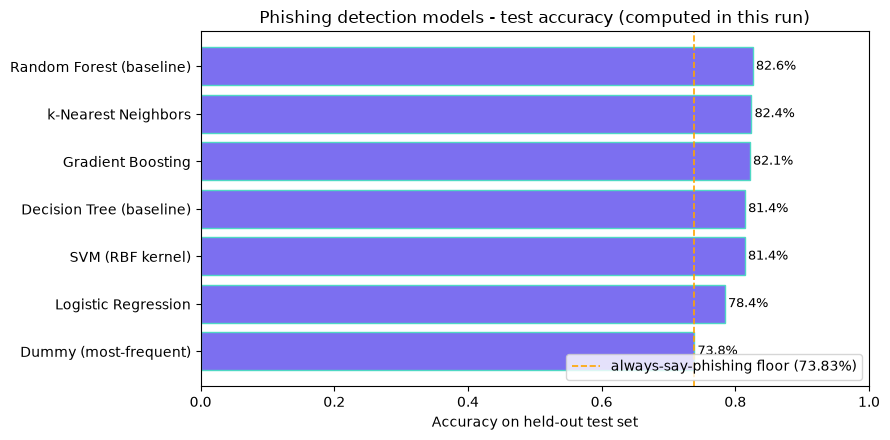

Saved: results/model_accuracy_comparison.png


In [8]:
# Accuracy chart, saved next to the results JSON for reuse in reports/pages.
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

%matplotlib inline
plot_df = merged.sort_values("accuracy", ascending=True)
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(plot_df["model"], plot_df["accuracy"], color="#7c6ff0", edgecolor="#4fd8c4")
ax.axvline(test_phishing_share, color="orange", linestyle="--", linewidth=1.2,
           label=f"always-say-phishing floor ({test_phishing_share:.2%})")
for bar, v in zip(bars, plot_df["accuracy"]):
    ax.text(v + 0.005, bar.get_y() + bar.get_height() / 2, f"{v:.1%}", va="center", fontsize=9)
ax.set_xlim(0, 1.0)
ax.set_xlabel("Accuracy on held-out test set")
ax.set_title("Phishing detection models - test accuracy (computed in this run)")
ax.legend(loc="lower right")
fig.tight_layout()
chart_path = RESULTS_DIR / "model_accuracy_comparison.png"
fig.savefig(chart_path, dpi=150)
plt.show()
print(f"Saved: {chart_path}")

## 6. Explanation groundwork — what pushed each prediction

The hybrid system's AI assistant needs **grounded reasons**, not guesses. The Random Forest exposes them: for every URL, each tree is walked from root to leaf, and the change in phishing probability along the path is recorded per feature. These deltas average across trees and sum (per tree) to `leaf probability - root probability`, so they add up to the final score — nothing is invented.

This is the same attribution logic used by the Midterm website's URL analyzer (`docs/js/analyzer.js`), implemented here in Python on the freshly trained forest. In the next assignment step, these contributions will be sent to the Mission Comms chatbot so its explanations match the model's actual reasoning.

In [9]:
def random_forest_contributions(forest, x_row):
    # Per-feature change in phishing probability, averaged over all trees.
    contributions = {f: 0.0 for f in FEATURE_ORDER}
    n_trees = len(forest.estimators_)
    for est in forest.estimators_:
        tree = est.tree_
        node = 0
        while tree.children_left[node] != -1:
            f_idx = int(tree.feature[node])
            nxt = (tree.children_left[node] if x_row[f_idx] <= tree.threshold[node]
                   else tree.children_right[node])
            parent = tree.value[node][0]
            child = tree.value[nxt][0]
            parent_p = parent[1] / parent.sum()
            child_p = child[1] / child.sum()
            contributions[FEATURE_ORDER[f_idx]] += child_p - parent_p
            node = nxt
    return {k: v / n_trees for k, v in contributions.items()}

proba = baseline_rf.predict_proba(X_test)[:, 1]
sample_idx = [int(i) for i in np.linspace(0, len(X_test) - 1, 4, dtype=int)]

explanation_examples = []
for i in sample_idx:
    row = X_test.iloc[i].to_numpy()
    contribs = random_forest_contributions(baseline_rf, row)
    top = sorted(contribs.items(), key=lambda kv: abs(kv[1]), reverse=True)[:5]
    actual = int(y_test.iloc[i])
    pred = int(rf_preds[i])
    explanation_examples.append({
        "test_row": i, "actual": actual, "predicted": pred,
        "phishing_probability": float(proba[i]),
        "top_contributions": [{"feature": f, "delta": float(d)} for f, d in top],
    })
    label = "PHISHING" if pred else "LEGITIMATE"
    actual_label = "phishing" if actual else "legitimate"
    print(f"\nTest row {i}: predicted {label} "
          f"(phishing probability {proba[i]:.3f}; actual: {actual_label})")
    for f, d in top:
        direction = "toward phishing" if d > 0 else "toward legitimate"
        print(f"    {f:14s} {d:+.4f}  ({direction})")

# Sanity check: contributions must reconstruct the probability (from the root base rate).
base_rate = float(np.mean([est.tree_.value[0][0][1] / est.tree_.value[0][0].sum()
                           for est in baseline_rf.estimators_]))
row0 = X_test.iloc[sample_idx[0]].to_numpy()
recon = base_rate + sum(random_forest_contributions(baseline_rf, row0).values())
recon_err = float(abs(recon - proba[sample_idx[0]]))
print(f"\nSanity check -- base rate {base_rate:.4f} + contributions = {recon:.4f}; "
      f"predict_proba = {proba[sample_idx[0]]:.4f}; error = {recon_err:.2e}")
assert recon_err < 1e-6, "Contribution attribution does not reconstruct the probability!"


Test row 0: predicted PHISHING (phishing probability 0.517; actual: legitimate)
    n_slash        -0.1963  (toward legitimate)
    n_hypens       +0.0409  (toward phishing)
    n_dots         -0.0368  (toward legitimate)
    n_equal        -0.0340  (toward legitimate)
    n_redirection  +0.0300  (toward phishing)

Test row 1455: predicted PHISHING (phishing probability 0.745; actual: phishing)
    n_slash        +0.0797  (toward phishing)
    n_hypens       -0.0467  (toward legitimate)
    url_length     +0.0380  (toward phishing)
    n_equal        -0.0371  (toward legitimate)
    n_redirection  +0.0322  (toward phishing)

Test row 2911: predicted PHISHING (phishing probability 0.940; actual: phishing)
    n_at           +0.1582  (toward phishing)
    n_equal        +0.0779  (toward phishing)
    n_slash        -0.0272  (toward legitimate)
    url_length     +0.0195  (toward phishing)
    n_redirection  -0.0178  (toward legitimate)

Test row 4367: predicted PHISHING (phishing probab

## 7. Save machine-readable results

Everything above is written to `results/experiments_results.json`. The `hybrid_system` section is intentionally saved with `null` metrics and status `not-yet-implemented` — the hybrid system has not been built or evaluated yet, and no results may be invented for it. A later step will fill that section with real measurements.

In [10]:
results = {
    "metadata": {
        "assignment": 6,
        "step": "2 - machine learning experiments",
        "generated_utc": datetime.now(timezone.utc).isoformat(),
        "python": sys.version.split()[0],
        "pandas": pd.__version__, "numpy": np.__version__,
        "scikit_learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
        "random_state": RANDOM_STATE,
        "feature_order": FEATURE_ORDER,
        "dataset_source": "https://www.kaggle.com/datasets/danielfernandon/web-page-phishing-dataset",
        "reference_notebook": "https://www.kaggle.com/code/mrudhuhas/advanced-url-analysis-for-phishing-detection/notebook",
    },
    "dataset": {
        "original_rows": int(df_raw.shape[0]),
        "duplicate_rows_removed": n_dupes,
        "cleaned_rows": int(df.shape[0]),
        "legitimate_rows": int(counts.get(0, 0)),
        "phishing_rows": int(counts.get(1, 0)),
        "train_rows": int(len(X_train)),
        "test_rows": int(len(X_test)),
        "test_phishing_share": test_phishing_share,
    },
    "baseline_replication": {
        "reference_note": "Reference accuracies reported in the Midterm notebook (Google Colab).",
        "decision_tree": {
            "reference_accuracy": REFERENCE_DT_ACCURACY,
            "actual_accuracy_this_run": float(dt_acc),
            "delta": float(dt_acc - REFERENCE_DT_ACCURACY),
            "exact_match": dt_exact,
        },
        "random_forest": {
            "reference_accuracy": REFERENCE_RF_ACCURACY,
            "actual_accuracy_this_run": float(rf_acc),
            "delta": float(rf_acc - REFERENCE_RF_ACCURACY),
            "exact_match": rf_exact,
        },
    },
    "model_comparison": json.loads(merged.to_json(orient="records")),
    "explanation_groundwork": {
        "method": ("per-tree root-to-leaf path attribution on the Random Forest "
                   "(same logic as the Midterm site's analyzer.js)"),
        "sanity_check_reconstruction_error": recon_err,
        "examples": explanation_examples,
    },
    "hybrid_system": {
        "status": "not-yet-implemented",
        "accuracy": None, "precision": None, "recall": None, "f1": None,
        "note": ("The classifier + AI explanation assistant has not been built or "
                 "evaluated yet; these fields are intentionally null."),
    },
}

RESULTS_DIR.mkdir(exist_ok=True)
out_path = RESULTS_DIR / "experiments_results.json"
out_path.write_text(json.dumps(results, indent=2))
print(f"Saved: {out_path.resolve()}")
print(f"Models compared: {len(merged)} | explanation examples: {len(explanation_examples)}")
if IN_COLAB:
    print("Colab tip: download the file, or copy the JSON printed by: print(out_path.read_text())")

Saved: /Users/joselyncarvajal/TECH3498/Assignment6/results/experiments_results.json
Models compared: 7 | explanation examples: 4


## Summary and next steps

- The Midterm baseline was retrained and checked against its reference accuracies (Section 2 shows the actual match result for your run).
- Four additional models were trained and compared on the identical split, with 5-fold cross-validation for stability (Sections 3–5).
- Per-prediction feature contributions were produced for sample rows — this is the grounded input the AI explanation assistant will receive in the next step (Section 6).
- `results/experiments_results.json` now holds every computed number in machine-readable form.

**Next steps (later Assignment 6 steps)**

1. Connect the trained Random Forest to the Mission Comms chatbot (Cloudflare Worker + Gemini), sending the verdict and feature contributions as context so explanations are grounded in the model's actual reasoning.
2. Evaluate explanation quality (accuracy of explanations + user understanding), then fill the `hybrid_system` section of the results JSON with real measurements.
3. Update the `ai-research.html` Results and Comparison placeholders with the numbers computed here.

**Credits:** Web Page Phishing Dataset — Daniel Fernandon (Kaggle). Reference notebook — mrudhuhas (Kaggle). Libraries — pandas, scikit-learn, numpy, matplotlib. Neither the dataset nor the reference notebook was created by me.